In [17]:
import os, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import (HistGradientBoostingRegressor, HistGradientBoostingClassifier,
                              RandomForestRegressor, RandomForestClassifier)
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings("ignore")

DATA = Path(".")     
REL = 0.9                                          
N_BOOT = 150 if FAST else 500
GRID = [10, 20, 50, 100, 200, 500, 1000, 2000, 5000, 10000, "all"]
BASE_DRAWS = {10: 60, 20: 60, 50: 40, 100: 40, 200: 30, 500: 30, 1000: 20, 2000: 20, 5000: 10, 10000: 6, "all": 1}
n_draws = lambda n: BASE_DRAWS[n] if not FAST else max(3, BASE_DRAWS[n] // 4)
N_TREES = 60 if FAST else 200
PROB_FLOOR = 1e-3
CLASSES = ["different_job", "no_job", "same_job"]
cmap = {c: i for i, c in enumerate(CLASSES)}
rng_boot = np.random.default_rng(12345)
VARIANTS = ["full", "reduced", "none", "shuffled"]

## Шаг 0. Проверка файлов

In [18]:
need = {"a1_pairs": ["a1_pairs.csv", "a1_pairs.csv.gz", "a1_pairs_csv.gz"],
        "a2_pairs": ["a2_pairs.csv", "a2_pairs.csv.gz", "a2_pairs_csv.gz"],
        "llm_predictions_a1.csv": ["llm_predictions_a1.csv"], "llm_predictions_a2.csv": ["llm_predictions_a2.csv"]}
ok_all = True
for label, names in need.items():
    found = [n for n in names if (DATA / n).exists()]
    print("OK  " if found else "НЕТ ", label, found[:1] if found else f"(ищу в {DATA.resolve()})")
    ok_all &= bool(found)
assert ok_all, "Не хватает файлов: положи их в одну папку с ноутбуком (см. список выше)."
_p1, _p2 = pd.read_csv(DATA / "llm_predictions_a1.csv"), pd.read_csv(DATA / "llm_predictions_a2.csv")
print("\nA1: строк по (модель, persona):"); print(_p1.groupby([c for c in ["model", "variant"] if c in _p1]).size())
print("A2: строк по (модель, persona):"); print(_p2.groupby([c for c in ["model", "variant"] if c in _p2]).size())
_none_ok = all((DATA / f).exists() for f in ["llm_predictions_none_a1.csv", "llm_predictions_none_a2.csv"])
print("\nПерезапуск none (llm_predictions_none_a1/a2.csv):", "найден, будет использован" if _none_ok else "НЕ найден: вариант none у Qwen 7B окажется пустым (модель отказывалась отвечать)")
print("\nЕсли тут две модели (qwen1.5b и qwen7b) по 4 persona, всё готово.")

OK   a1_pairs ['a1_pairs.csv.gz']
OK   a2_pairs ['a2_pairs.csv.gz']
OK   llm_predictions_a1.csv ['llm_predictions_a1.csv']
OK   llm_predictions_a2.csv ['llm_predictions_a2.csv']

A1: строк по (модель, persona):
model     variant 
qwen1.5b  full        1000
          none        1000
          reduced     1000
          shuffled    1000
qwen7b    full        1000
          none        1000
          reduced     1000
          shuffled    1000
dtype: int64
A2: строк по (модель, persona):
model     variant 
qwen1.5b  full        1500
          none        1500
          reduced     1500
          shuffled    1500
qwen7b    full        1500
          none        1500
          reduced     1500
          shuffled    1500
dtype: int64

Перезапуск none (llm_predictions_none_a1/a2.csv): найден, будет использован

Если тут две модели (qwen1.5b и qwen7b) по 4 persona, всё готово.


## 1. Данные и временной сплит
train: `target_year <= 2021`, test: `target_year >= 2024`. Будущее в train не попадает.

In [3]:
def read_pairs(name):
    for f in (DATA / f"{name}_pairs.csv", DATA / f"{name}_pairs.csv.gz", DATA / f"{name}_pairs_csv.gz"):
        if f.exists(): return pd.read_csv(f)
    raise FileNotFoundError(f"нет {name}_pairs в {DATA.resolve()}")

a1, a2 = read_pairs("a1"), read_pairs("a2")
a1_tr = a1[a1.target_year <= 2021].reset_index(drop=True); a1_te = a1[a1.target_year >= 2024].reset_index(drop=True)
a2_tr = a2[a2.target_year <= 2021].dropna(subset=["target"]).reset_index(drop=True); a2_te = a2[a2.target_year >= 2024].dropna(subset=["target"]).reset_index(drop=True)
print("A1 train/test:", len(a1_tr), len(a1_te), "| A2 train/test:", len(a2_tr), len(a2_te))
pos1 = pd.Series(np.arange(len(a1_te)), index=a1_te.row_id.values)
pos2 = pd.Series(np.arange(len(a2_te)), index=a2_te.row_id.values)
y2_tr = a2_tr.target.map(cmap).values; y2_te = a2_te.target.map(cmap).values
print("Доли A2 train:", dict(zip(CLASSES, np.bincount(y2_tr, minlength=3) / len(y2_tr))))
print("Доли A2 test: ", dict(zip(CLASSES, np.bincount(y2_te, minlength=3) / len(y2_te))))

A1 train/test: 63832 11233 | A2 train/test: 79248 13623
Доли A2 train: {'different_job': 0.10585756107409651, 'no_job': 0.0818317181506158, 'same_job': 0.8123107207752877}
Доли A2 test:  {'different_job': 0.0822139029582324, 'no_job': 0.047566615282977315, 'same_job': 0.8702194817587903}


## 2. Предсказания LLM (из Colab)

In [16]:
def metric_rows_a2(P, y):
    P = np.clip(P, PROB_FLOOR, 1); P = P / P.sum(1, keepdims=True)
    return ((P - np.eye(3)[y]) ** 2).sum(1), -np.log(P[np.arange(len(y)), y])

PRIOR_FULL = (np.bincount(y2_tr, minlength=3) + 1) / (len(y2_tr) + 3)    
d1 = pd.read_csv(DATA / "llm_predictions_a1.csv"); d2 = pd.read_csv(DATA / "llm_predictions_a2.csv")
if "variant" not in d1: d1["variant"] = "full"
if "variant" not in d2: d2["variant"] = d2.get("variant", "full"); d2["variant"] = d2["variant"].replace({"plain": "full"})

# NONE_MERGE
for _f1, _f2 in [("llm_predictions_none_a1.csv", "llm_predictions_none_a2.csv")]:
    if (DATA / _f1).exists() and (DATA / _f2).exists():
        _n1, _n2 = pd.read_csv(DATA / _f1), pd.read_csv(DATA / _f2)
        _n1["variant"] = "none"; _n2["variant"] = "none"
        d1 = pd.concat([d1[~((d1.variant == "none") & d1.model.isin(_n1.model.unique()))], _n1], ignore_index=True)
        d2 = pd.concat([d2[~((d2.variant == "none") & d2.model.isin(_n2.model.unique()))], _n2], ignore_index=True)
        print("Вариант none взят из перезапуска:", sorted(_n1.model.unique()))

REFS1, REFS2 = {}, {}
for (m, v), g in d1.groupby(["model", "variant"]):
    g = g.drop_duplicates("row_id"); g = g[g.row_id.isin(pos1.index)]
    idx = pos1[g.row_id.values].values
    pred = g.pred_food.values.astype(float).copy(); bad = ~np.isfinite(pred)
    pred[bad] = a1_te.food.values[idx][bad]
    REFS1[(m, v)] = {"idx": idx, "err": np.abs(a1_te.target_food.values[idx] - pred), "parse": 1 - bad.mean()}
for (m, v), g in d2.groupby(["model", "variant"]):
    g = g.drop_duplicates("row_id"); g = g[g.row_id.isin(pos2.index)]
    idx = pos2[g.row_id.values].values
    P = g[[f"p_{c}" for c in CLASSES]].values.astype(float); bad = ~np.isfinite(P).all(1)
    P[bad] = PRIOR_FULL
    b, l = metric_rows_a2(P, y2_te[idx])
    REFS2[(m, v)] = {"idx": idx, "brier": b, "ll": l, "parse": 1 - bad.mean()}

# VARIANT_GUARD
for _name, _R in (("A1", REFS1), ("A2", REFS2)):
    for _k in [k for k, v in _R.items() if v["parse"] < 0.5]:
        print(f"{_name} {_k}: parse_rate={_R[_k]['parse']:.3f} < 0.5 → вариант ИСКЛЮЧЁН (модель не отвечает в нужном формате)")
        del _R[_k]

# NO_FULL_GUARD
for _name, _R in (("A1", REFS1), ("A2", REFS2)):
    _with_full = {m for (m, v) in _R if v == "full"}
    for _k in [k for k in _R if k[0] not in _with_full]:
        print(f" {_name} {_k}: у модели нет варианта full → исключена из анализа")
        del _R[_k]

print("A1:", {k: f"n={len(v['idx'])}, parse={v['parse']:.3f}" for k, v in REFS1.items()})
print("A2:", {k: f"n={len(v['idx'])}, parse={v['parse']:.3f}" for k, v in REFS2.items()})
U1 = np.unique(np.concatenate([r["idx"] for r in REFS1.values()]))
U2 = np.unique(np.concatenate([r["idx"] for r in REFS2.values()]))

Вариант none взят из перезапуска: ['qwen1.5b', 'qwen7b', 'smollm1.7b']
 A1 ('smollm1.7b', 'none'): у модели нет варианта full → исключена из анализа
 A2 ('smollm1.7b', 'none'): у модели нет варианта full → исключена из анализа
A1: {('qwen1.5b', 'full'): 'n=1000, parse=1.000', ('qwen1.5b', 'none'): 'n=1000, parse=1.000', ('qwen1.5b', 'reduced'): 'n=1000, parse=1.000', ('qwen1.5b', 'shuffled'): 'n=1000, parse=1.000', ('qwen7b', 'full'): 'n=1000, parse=0.998', ('qwen7b', 'none'): 'n=1000, parse=1.000', ('qwen7b', 'reduced'): 'n=1000, parse=1.000', ('qwen7b', 'shuffled'): 'n=1000, parse=1.000'}
A2: {('qwen1.5b', 'full'): 'n=1500, parse=1.000', ('qwen1.5b', 'none'): 'n=1500, parse=1.000', ('qwen1.5b', 'reduced'): 'n=1500, parse=1.000', ('qwen1.5b', 'shuffled'): 'n=1500, parse=1.000', ('qwen7b', 'full'): 'n=1500, parse=1.000', ('qwen7b', 'none'): 'n=1500, parse=1.000', ('qwen7b', 'reduced'): 'n=1500, parse=1.000', ('qwen7b', 'shuffled'): 'n=1500, parse=1.000'}


## 3. Baseline без персонального моделирования

In [5]:
def baselines_a1(idx):
    y = a1_te.target_food.values[idx]
    return {"persistence": np.abs(y - a1_te.food.values[idx]),
            "train_median": np.abs(y - a1_tr.target_food.median()),
            "train_mean": np.abs(y - a1_tr.target_food.mean())}

def baselines_a2(idx):
    y = y2_te[idx]; raw = np.bincount(y2_tr, minlength=3) / len(y2_tr)
    maj = np.full(3, PROB_FLOOR); maj[raw.argmax()] = 1
    out = {}
    for name, p in [("train_rate", raw), ("smoothed_prior", PRIOR_FULL), ("majority", maj)]:
        out[name] = metric_rows_a2(np.tile(p, (len(idx), 1)), y)[0]
    return out

rows = []
for (m, v), R in REFS1.items():
    row = {"task": "A1 MAE", "model": m, "persona": v, "LLM": R["err"].mean()}
    row.update({k: e.mean() for k, e in baselines_a1(R["idx"]).items()}); rows.append(row)
for (m, v), R in REFS2.items():
    row = {"task": "A2 Brier", "model": m, "persona": v, "LLM": R["brier"].mean()}
    row.update({k: e.mean() for k, e in baselines_a2(R["idx"]).items()}); rows.append(row)
BASE_TABLE = pd.DataFrame(rows)
pd.set_option("display.width", 220); pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
BASE_TABLE

,task,model,persona,LLM,persistence,train_median,train_mean,train_rate,smoothed_prior,majority
0,A1 MAE,qwen1.5b,full,"7,132.4742","6,644.5650","15,767.3130","14,158.2314",NaN,NaN,NaN
1,A1 MAE,qwen1.5b,none,"12,532.7130","6,644.5650","15,767.3130","14,158.2314",NaN,NaN,NaN
2,A1 MAE,qwen1.5b,reduced,"22,168.9758","6,644.5650","15,767.3130","14,158.2314",NaN,NaN,NaN
3,A1 MAE,qwen1.5b,shuffled,"15,122.0585","6,644.5650","15,767.3130","14,158.2314",NaN,NaN,NaN
4,A1 MAE,qwen7b,full,"6,873.1708","6,644.5650","15,767.3130","14,158.2314",NaN,NaN,NaN
5,A1 MAE,qwen7b,none,"12,532.7130","6,644.5650","15,767.3130","14,158.2314",NaN,NaN,NaN
6,A1 MAE,qwen7b,reduced,"6,663.7113","6,644.5650","15,767.3130","14,158.2314",NaN,NaN,NaN
7,A1 MAE,qwen7b,shuffled,"15,874.6711","6,644.5650","15,767.3130","14,158.2314",NaN,NaN,NaN
8,A2 Brier,qwen1.5b,full,0.3818,NaN,NaN,NaN,0.2457,0.2457,0.2685
9,A2 Brier,qwen1.5b,none,0.3246,NaN,NaN,NaN,0.2457,0.2457,0.2685


## 4. ML learning curves

In [6]:
A1_RAW = ["year", "hh_size", "employed_count", "children_count", "adult_count"]
med1 = {c: a1_tr[c].median() for c in A1_RAW + ["income"]}
def feats_a1(d):
    X = pd.DataFrame(index=d.index)
    X["lf"] = np.log(d.food.clip(lower=1))
    X["li"] = np.log1p(d.income.fillna(med1["income"]).clip(lower=0)); X["inc_na"] = d.income.isna().astype(int)
    pf = d.prev_food.where(d.prev_food > 0).fillna(d.food)
    X["lpf"] = np.log(pf.clip(lower=1)); X["hist_na"] = d.prev_food.isna().astype(int)
    X["lpi"] = np.log1p(d.prev_income.fillna(d.income).fillna(med1["income"]).clip(lower=0))
    X["dlf"] = X.lf - X.lpf
    for c in A1_RAW: X[c] = d[c].fillna(med1[c])
    return X
Xa1_tr, Xa1_te = feats_a1(a1_tr), feats_a1(a1_te)
ya1_tr = np.log(a1_tr.target_food / a1_tr.food).values        # цель: лог-изменение расходов

A2_RAW = ["year", "age", "sex", "education", "settlement", "marital", "occupation", "wage", "hours", "tenure",
          "history_years", "wage_change", "occupation_changed", "prior_job_change"]
med2 = a2_tr[A2_RAW].median().fillna(0)
def feats_a2(d):
    X = d[A2_RAW].copy()
    for c in ["wage", "hours", "wage_change", "tenure"]: X[c + "_na"] = X[c].isna().astype(int)
    return X.fillna(med2)
Xa2_tr, Xa2_te = feats_a2(a2_tr), feats_a2(a2_te)

def a1_models(n, seed):
    r = np.random.default_rng(seed)
    idx = r.choice(len(a1_tr), n, replace=False) if n < len(a1_tr) else np.arange(len(a1_tr))
    X, y = Xa1_tr.iloc[idx], ya1_tr[idx]; Xt = Xa1_te.iloc[U1]; base = a1_te.food.values[U1]; out = {}
    out["drift"] = base * np.exp(np.median(y)) * np.ones(len(U1))
    sc = StandardScaler().fit(X); rg = Ridge(alpha=10).fit(sc.transform(X), y)
    out["ridge"] = base * np.exp(rg.predict(sc.transform(Xt)) + np.median(y - rg.predict(sc.transform(X))))
    out["rf"] = base * np.exp(RandomForestRegressor(n_estimators=N_TREES, min_samples_leaf=5, max_features=0.6, n_jobs=-1, random_state=seed).fit(X, y).predict(Xt))
    out["gbm"] = base * np.exp(HistGradientBoostingRegressor(loss="absolute_error", max_iter=150, learning_rate=0.08, max_leaf_nodes=15, random_state=seed).fit(X, y).predict(Xt))
    return {m: {"err": np.abs(a1_te.target_food.values[U1] - p)} for m, p in out.items()}

def proba3(model, X):
    P = np.full((len(X), 3), PROB_FLOOR); P[:, model.classes_] = np.maximum(model.predict_proba(X), PROB_FLOOR)
    return P / P.sum(1, keepdims=True)

def a2_models(n, seed):
    r = np.random.default_rng(seed)
    idx = r.choice(len(a2_tr), n, replace=False) if n < len(a2_tr) else np.arange(len(a2_tr))
    X, y = Xa2_tr.iloc[idx], y2_tr[idx]; Xt = Xa2_te.iloc[U2]
    prior = (np.bincount(y, minlength=3) + 1) / (len(y) + 3); Ps = {"freq": np.tile(prior, (len(U2), 1))}
    if len(np.unique(y)) >= 2:                      # если класс один, ML = prior (нормальная часть малых данных)
        sc = StandardScaler().fit(X)
        Ps["logit"] = proba3(LogisticRegression(C=0.3, max_iter=300).fit(sc.transform(X), y), sc.transform(Xt))
        Ps["rf"] = proba3(RandomForestClassifier(n_estimators=N_TREES, min_samples_leaf=5, n_jobs=-1, random_state=seed).fit(X, y), Xt)
        Ps["gbm"] = proba3(HistGradientBoostingClassifier(max_iter=150, learning_rate=0.08, max_leaf_nodes=15, random_state=seed).fit(X, y), Xt)
    else:
        for k in ["logit", "rf", "gbm"]: Ps[k] = Ps["freq"]
    res = {}
    for k, P in Ps.items():
        b, l = metric_rows_a2(P, y2_te[U2]); res[k] = {"brier": b, "ll": l}
    return res

def run_curves(model_fn, ntrain):
    out = {}
    for n in GRID:
        nn = ntrain if n == "all" else n; t0 = time.time()
        recs = [model_fn(nn, 1000 + s) for s in range(n_draws(n))]
        for m in recs[0]:
            out.setdefault(m, {})[nn] = {k: np.array([r[m][k] for r in recs]) for k in recs[0][m]}
        print(f"  n={nn:>6} draws={len(recs):>3} {time.time()-t0:5.1f}s", flush=True)
    return out

print("A1 ..."); CUR1 = run_curves(a1_models, len(a1_tr))
print("A2 ..."); CUR2 = run_curves(a2_models, len(a2_tr))

A1 ...
  n=    10 draws= 60  49.1s
  n=    20 draws= 60  49.9s
  n=    50 draws= 40  39.5s
  n=   100 draws= 40  52.2s
  n=   200 draws= 30  59.8s
  n=   500 draws= 30 136.2s
  n=  1000 draws= 20  63.0s
  n=  2000 draws= 20  69.6s
  n=  5000 draws= 10  41.4s
  n= 10000 draws=  6  34.7s
  n= 63832 draws=  1  23.4s
A2 ...
  n=    10 draws= 60  58.2s
  n=    20 draws= 60  67.4s
  n=    50 draws= 40  68.6s
  n=   100 draws= 40 103.7s
  n=   200 draws= 30 122.6s
  n=   500 draws= 30 221.3s
  n=  1000 draws= 20 156.8s
  n=  2000 draws= 20 167.5s
  n=  5000 draws= 10 28936.6s
  n= 10000 draws=  6  30.4s
  n= 79248 draws=  1   5.9s


## 5. ESS

In [8]:
def ess_from(vals_by_n, thr, rel=REL):
    for n in sorted(vals_by_n):
        if (vals_by_n[n] <= thr).mean() >= rel: return n
    return np.inf

def ess_paired(cur_m, key, ref_err, ref_idx, U, groups_all):
    cols = np.searchsorted(U, ref_idx)
    M = {n: cur_m[n][key][:, cols] for n in cur_m}
    point = ess_from({n: M[n].mean(1) for n in M}, ref_err.mean())
    uniq, inv = np.unique(groups_all[ref_idx], return_inverse=True)
    members = [np.where(inv == k)[0] for k in range(len(uniq))]
    boots = []
    for _ in range(N_BOOT):
        rows = np.concatenate([members[k] for k in rng_boot.integers(0, len(uniq), len(uniq))])
        boots.append(ess_from({n: M[n][:, rows].mean(1) for n in M}, ref_err[rows].mean()))
    b = np.array(boots, dtype=float)
    q = lambda p: np.percentile(b, p, method="nearest")
    return point, q(2.5), q(97.5), np.isinf(b).mean()

fmt = lambda v: "∞" if np.isinf(v) else f"{int(v)}"

ess_rows = []
for (m, v), R in REFS1.items():
    for ml in CUR1:
        p, lo, hi, pinf = ess_paired(CUR1[ml], "err", R["err"], R["idx"], U1, a1_te.panel_id.values)
        ess_rows.append({"task": "A1", "LLM": m, "persona": v, "ML": ml, "ESS": p, "lo": lo, "hi": hi, "P(∞)": pinf})
for (m, v), R in REFS2.items():
    for ml in CUR2:
        p, lo, hi, pinf = ess_paired(CUR2[ml], "brier", R["brier"], R["idx"], U2, a2_te.panel_id.values)
        ess_rows.append({"task": "A2", "LLM": m, "persona": v, "ML": ml, "ESS": p, "lo": lo, "hi": hi, "P(∞)": pinf})
ESS = pd.DataFrame(ess_rows)
ESS_show = ESS.assign(ESS=ESS.ESS.map(fmt), CI95=[f"[{fmt(a)}; {fmt(b)}]" for a, b in zip(ESS.lo, ESS.hi)]).drop(columns=["lo", "hi"])
ESS_show

,task,LLM,persona,ML,ESS,P(∞),CI95
0,A1,qwen1.5b,full,drift,50,0.0100,[50; 200]
1,A1,qwen1.5b,full,ridge,1000,0.0000,[200; 2000]
2,A1,qwen1.5b,full,rf,63832,0.2080,[5000; ∞]
3,A1,qwen1.5b,full,gbm,1000,0.0000,[100; 63832]
4,A1,qwen1.5b,none,drift,10,0.0000,[10; 10]
...,...,...,...,...,...,...,...
59,A2,qwen7b,reduced,gbm,10,0.0000,[10; 10]
60,A2,qwen7b,shuffled,freq,100,0.0000,[50; 100]
61,A2,qwen7b,shuffled,logit,500,0.0000,[500; 1000]
62,A2,qwen7b,shuffled,rf,20,0.0000,[20; 20]


## 6. Prior gain и personalization gain

In [9]:
def boot_gain(base, new, groups, repeats=500, seed=7):
    uniq, inv = np.unique(groups, return_inverse=True); r = np.random.default_rng(seed)
    bs = np.bincount(inv, weights=base); ns = np.bincount(inv, weights=new); cn = np.bincount(inv)
    est = 100 * (base.mean() - new.mean()) / base.mean(); d = []
    for _ in range(repeats):
        s = r.integers(0, len(uniq), len(uniq)); b = bs[s].sum() / cn[s].sum(); n_ = ns[s].sum() / cn[s].sum(); d.append(100 * (b - n_) / b)
    lo, hi = np.quantile(d, [0.025, 0.975]); return est, lo, hi

def paired_on_common(RA, RB, key):
    common, ia, ib = np.intersect1d(RA["idx"], RB["idx"], return_indices=True)
    return common, RA[key][ia], RB[key][ib]

gain_rows = []
for task, REFS, key, te, base_fn in [("A1", REFS1, "err", a1_te, baselines_a1), ("A2", REFS2, "brier", a2_te, baselines_a2)]:
    bname = "persistence" if task == "A1" else "train_rate"
    for (m, v), R in REFS.items():
        base = base_fn(R["idx"])[bname]
        est, lo, hi = boot_gain(base, R[key], te.panel_id.values[R["idx"]])
        gain_rows.append({"task": task, "LLM": m, "persona": v, "kind": f"prior gain vs {bname}, %", "est": est, "lo": lo, "hi": hi})
    for m in sorted({k[0] for k in REFS}):
        if (m, "full") not in REFS: continue
        for other in ["none", "shuffled", "reduced"]:
            if (m, other) not in REFS: continue
            common, e_other, e_full = paired_on_common(REFS[(m, other)], REFS[(m, "full")], key)
            est, lo, hi = boot_gain(e_other, e_full, te.panel_id.values[common])
            gain_rows.append({"task": task, "LLM": m, "persona": "full", "kind": f"personalization gain vs {other}, %", "est": est, "lo": lo, "hi": hi})
GAINS = pd.DataFrame(gain_rows)
GAINS

,task,LLM,persona,kind,est,lo,hi
0,A1,qwen1.5b,full,"prior gain vs persistence, %",-7.3430,-12.7806,-1.3112
1,A1,qwen1.5b,none,"prior gain vs persistence, %",-88.6160,-103.7413,-76.1307
2,A1,qwen1.5b,reduced,"prior gain vs persistence, %",-233.6407,-287.8680,-192.9550
3,A1,qwen1.5b,shuffled,"prior gain vs persistence, %",-127.5854,-147.0963,-110.6160
4,A1,qwen7b,full,"prior gain vs persistence, %",-3.4405,-5.9918,-0.8566
5,A1,qwen7b,none,"prior gain vs persistence, %",-88.6160,-103.7413,-76.1307
6,A1,qwen7b,reduced,"prior gain vs persistence, %",-0.2881,-0.9129,0.0859
7,A1,qwen7b,shuffled,"prior gain vs persistence, %",-138.9121,-159.2158,-119.9019
8,A1,qwen1.5b,full,"personalization gain vs none, %",43.0891,39.5638,46.5352
9,A1,qwen1.5b,full,"personalization gain vs shuffled, %",52.8340,49.1298,56.1255


## 7. Итоговая карта: задача - модель - persona-prior gain + personalization gain + ESS

In [19]:
best = ESS.sort_values("ESS").groupby(["task", "LLM", "persona"]).first().reset_index()[["task", "LLM", "persona", "ML", "ESS"]]
pg = GAINS[GAINS.kind.str.startswith("prior")][["task", "LLM", "persona", "est", "lo", "hi"]].rename(columns={"est": "prior_gain_%", "lo": "pg_lo", "hi": "pg_hi"})
pers = GAINS[GAINS.kind.str.contains("personalization")].pivot_table(index=["task", "LLM"], columns="kind", values="est").reset_index()
pers.columns = [c.replace("personalization gain vs ", "pers_vs_").replace(", %", "") if "personalization" in c else c for c in pers.columns]
MAP = best.merge(pg, on=["task", "LLM", "persona"], how="left").merge(pers, on=["task", "LLM"], how="left")
MAP["ESS"] = MAP.ESS.map(fmt)
MAP["вывод"] = np.where(MAP["pg_lo"] <= 0, "LLM не лучше baseline ESS не интерпретировать", "LLM лучше baseline")
MAP

,task,LLM,persona,ML,ESS,prior_gain_%,pg_lo,pg_hi,pers_vs_none,pers_vs_reduced,pers_vs_shuffled,вывод
0,A1,qwen1.5b,full,drift,50,-7.3430,-12.7806,-1.3112,43.0891,67.8268,52.8340,LLM не лучше baseline ESS не интерпретировать
1,A1,qwen1.5b,none,drift,10,-88.6160,-103.7413,-76.1307,43.0891,67.8268,52.8340,LLM не лучше baseline ESS не интерпретировать
2,A1,qwen1.5b,reduced,drift,10,-233.6407,-287.8680,-192.9550,43.0891,67.8268,52.8340,LLM не лучше baseline ESS не интерпретировать
3,A1,qwen1.5b,shuffled,drift,10,-127.5854,-147.0963,-110.6160,43.0891,67.8268,52.8340,LLM не лучше baseline ESS не интерпретировать
4,A1,qwen7b,full,drift,100,-3.4405,-5.9918,-0.8566,45.1582,-3.1433,56.7035,LLM не лучше baseline ESS не интерпретировать
5,A1,qwen7b,none,rf,10,-88.6160,-103.7413,-76.1307,45.1582,-3.1433,56.7035,LLM не лучше baseline ESS не интерпретировать
6,A1,qwen7b,reduced,drift,1000,-0.2881,-0.9129,0.0859,45.1582,-3.1433,56.7035,LLM не лучше baseline ESS не интерпретировать
7,A1,qwen7b,shuffled,gbm,10,-138.9121,-159.2158,-119.9019,45.1582,-3.1433,56.7035,LLM не лучше baseline ESS не интерпретировать
8,A2,qwen1.5b,full,freq,10,-55.3842,-65.0639,-45.6751,-17.6236,-9.0037,-3.0108,LLM не лучше baseline ESS не интерпретировать
9,A2,qwen1.5b,none,rf,10,-32.1029,-39.6066,-25.7036,-17.6236,-9.0037,-3.0108,LLM не лучше baseline ESS не интерпретировать


### Сводка ESS (full persona)
Главный результат задания в одной таблице: ESS по каждой LLM и каждой ML-модели.

In [11]:
ESS_SUMMARY = (ESS[ESS.persona == "full"].assign(ESS_N=lambda d: d.ESS.map(fmt))
               .pivot_table(index=["task", "LLM"], columns="ML", values="ESS_N", aggfunc="first"))
print("ESS (full persona): сколько реальных наблюдений нужно каждой ML-модели, чтобы сравняться с LLM. ∞ = не догнала.")
ESS_SUMMARY

ESS (full persona): сколько реальных наблюдений нужно каждой ML-модели, чтобы сравняться с LLM. ∞ = не догнала.


ML            drift freq    gbm logit     rf ridge
task LLM                                          
A1   qwen1.5b    50  NaN   1000   NaN  63832  1000
     qwen7b     100  NaN  63832   NaN      ∞  2000
A2   qwen1.5b   NaN   10     10    20     10   NaN
     qwen7b     NaN  500   5000  1000    100   NaN

## 8. Графики

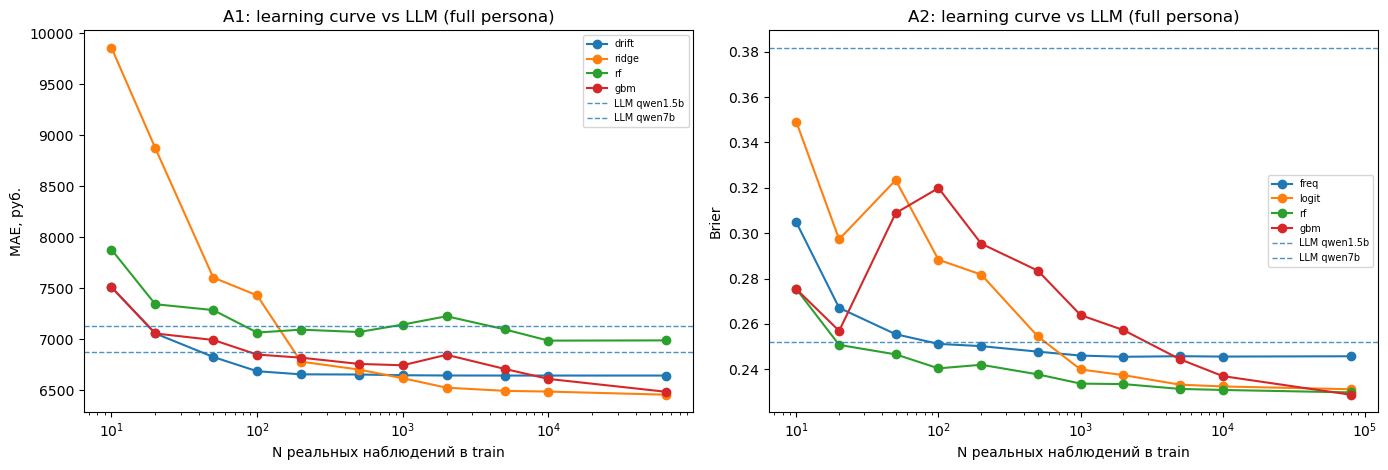

In [12]:
def plot_curve(ax, cur, key, refs, title, ylabel, only="full"):
    for m in cur:
        ns = sorted(cur[m]); ax.plot(ns, [cur[m][n][key].mean() for n in ns], "o-", label=m)
    for (mm, v), R in refs.items():
        if v == only: ax.axhline(R[key].mean(), ls="--", lw=1, alpha=.8, label=f"LLM {mm}")
    ax.set(xscale="log", xlabel="N реальных наблюдений в train", ylabel=ylabel, title=title); ax.legend(fontsize=7)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
plot_curve(ax[0], CUR1, "err", REFS1, "A1: learning curve vs LLM (full persona)", "MAE, руб.")
plot_curve(ax[1], CUR2, "brier", REFS2, "A2: learning curve vs LLM (full persona)", "Brier")
plt.tight_layout(); plt.savefig("fig_learning_curves.png", dpi=150); plt.show()

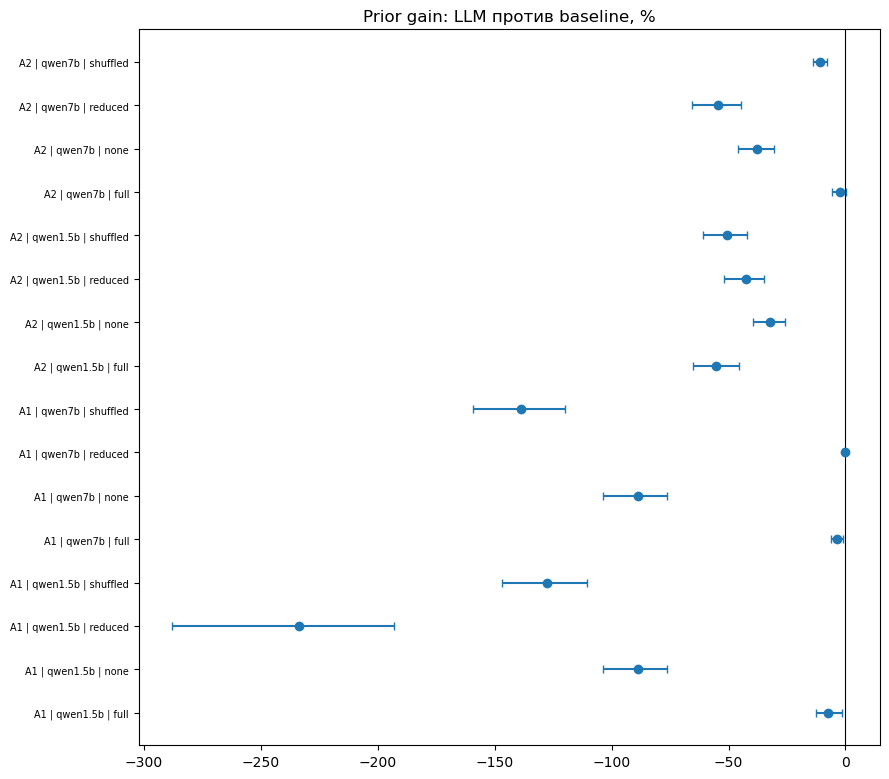

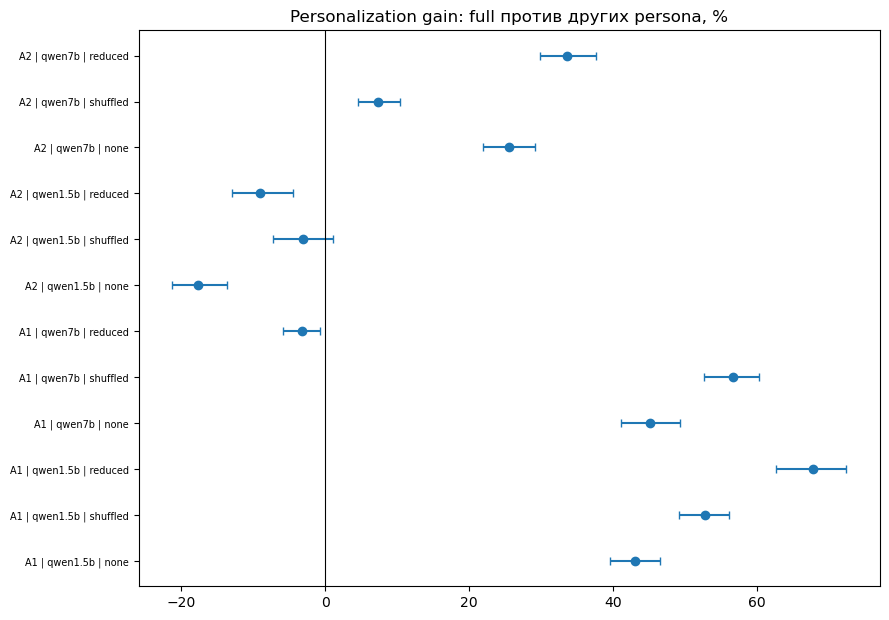

In [13]:
# Prior gain и personalization gain с доверительными интервалами
for kind_prefix, title, fname in [("prior", "Prior gain: LLM против baseline, %", "fig_prior_gain.png"),
                                  ("personalization", "Personalization gain: full против других persona, %", "fig_personalization.png")]:
    g = GAINS[GAINS.kind.str.startswith(kind_prefix)].copy()
    g["label"] = g.task + " | " + g.LLM + " | " + (g.persona if kind_prefix == "prior" else g.kind.str.extract(r"vs (\w+)")[0])
    fig, ax = plt.subplots(figsize=(9, 0.4 * len(g) + 1.5))
    y = np.arange(len(g)); ax.errorbar(g.est, y, xerr=[g.est - g.lo, g.hi - g.est], fmt="o", capsize=3)
    ax.axvline(0, color="k", lw=.8); ax.set_yticks(y); ax.set_yticklabels(g.label, fontsize=7); ax.set_title(title)
    plt.tight_layout(); plt.savefig(fname, dpi=150); plt.show()

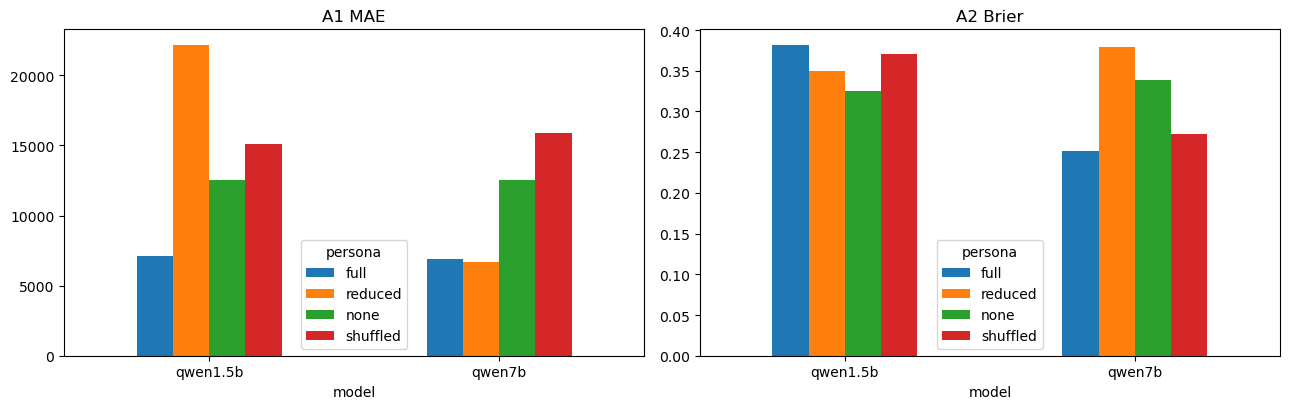

In [14]:
# Метрика против размера модели и persona (по full / none / shuffled)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for a, (task, REFS, key) in zip(ax, [("A1 MAE", REFS1, "err"), ("A2 Brier", REFS2, "brier")]):
    t = pd.DataFrame([{"model": m, "persona": v, "metric": R[key].mean()} for (m, v), R in REFS.items()]).pivot(index="model", columns="persona", values="metric")
    t[[c for c in VARIANTS if c in t.columns]].plot.bar(ax=a); a.set_title(task); a.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig("fig_models_personas.png", dpi=150); plt.show()

## 8. Сохранение

In [15]:
BASE_TABLE.to_csv("ess_baselines.csv", index=False); ESS.to_csv("ess_table.csv", index=False)
GAINS.to_csv("ess_gains.csv", index=False); MAP.to_csv("ess_map.csv", index=False)
print("Сохранено: ess_baselines.csv, ess_table.csv, ess_gains.csv, ess_map.csv + fig_*.png")

Сохранено: ess_baselines.csv, ess_table.csv, ess_gains.csv, ess_map.csv + fig_*.png
